In [1]:
import matplotlib.pyplot as plt
import numpy as np
import requests

# Exercises

For the exam, please prepare 2 exercises from this list.

## Q2: Planetary positions

The distances of the planets from the Sun (technically, their semi-major axes) are:

In [2]:
a = np.array([0.39, 0.72, 1.00, 1.52, 5.20, 9.54, 19.22, 30.06, 39.48])

These are in units where the Earth-Sun distance is 1 (astronomical units).

The corresponding periods of their orbits (how long they take to go once around the Sun) are, in years

In [3]:
P = np.array([0.24, 0.62, 1.00, 1.88, 11.86, 29.46, 84.01, 164.8, 248.09])

Finally, the names of the planets corresponding to these are:

In [4]:
names = ["Mercury", "Venus", "Earth", "Mars", "Jupiter", "Saturn", 
         "Uranus", "Neptune", "Pluto"]

(technically, pluto isn't a planet anymore, but we still love it :)

  * Plot as points, the periods vs. distances for each planet on a log-log plot.

  * Write the name of the planet next to the point for that planet on the plot

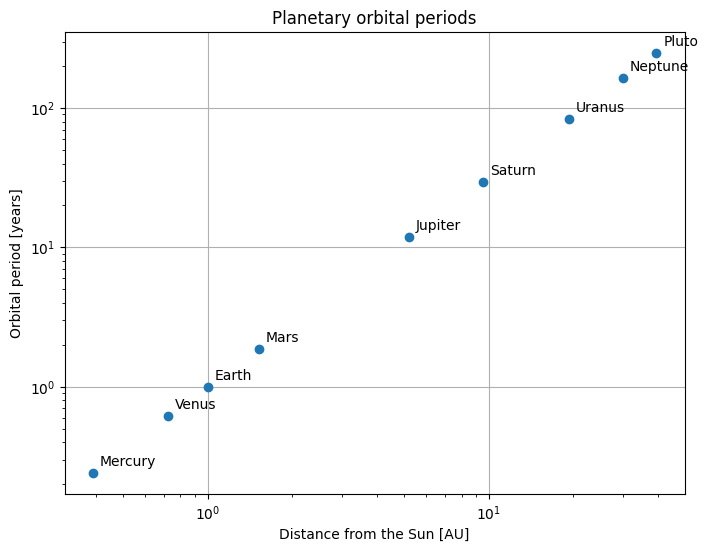

In [5]:
fig, ax = plt.subplots(figsize=(8, 6))

ax.loglog(a, P, "o")

for distance, period, name in zip(a, P, names):
    ax.annotate(
        name,
        (distance, period),
        xytext=(5, 5),
        textcoords="offset points"
    )

ax.set_xlabel("Distance from the Sun [AU]")
ax.set_ylabel("Orbital period [years]")
ax.set_title("Planetary orbital periods")
ax.grid(True)

plt.show()

## Q3: A perfect circle

For an angle $\theta$ in the range $\theta \in [0, 2\pi]$, the polar equations of a circle of radius $R$ are:

$$x = R\cos(\theta)$$

$$y = R\sin(\theta)$$

We want to draw a circle.   

  * Create an array to hold the theta values&mdash;the more we use, the smoother the circle will be
  * Create `x` and `y` arrays from `theta` for your choice of $R$
  * Plot `y` vs. `x`
  
Now, look up the matplotlib `fill()` function, and draw a circle filled in with a solid color.

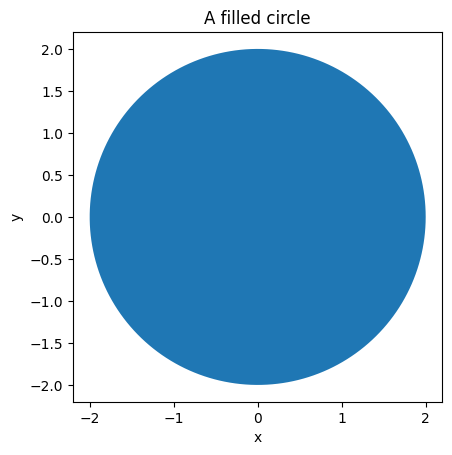

In [6]:
R = 2.0

theta = np.linspace(0, 2*np.pi, 200)

x = R * np.cos(theta)
y = R * np.sin(theta)

fig, ax = plt.subplots()

ax.fill(x, y)
ax.set_aspect("equal")

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("A filled circle")

plt.show()

Generalize your circle drawing commands to produce a function, 
```
draw_circle(x0, y0, R, color)
```
that draws the circle.  Here, `(x0, y0)` is the center of the circle, `R` is the radius, and `color` is the color of the circle.  

Now randomly draw 10 circles at different locations, with random radii, and random colors on the same plot.

In [7]:
def draw_circle(x0, y0, R, color):
    theta = np.linspace(0, 2*np.pi, 200)

    x = x0 + R * np.cos(theta)
    y = y0 + R * np.sin(theta)

    plt.fill(x, y, color=color)

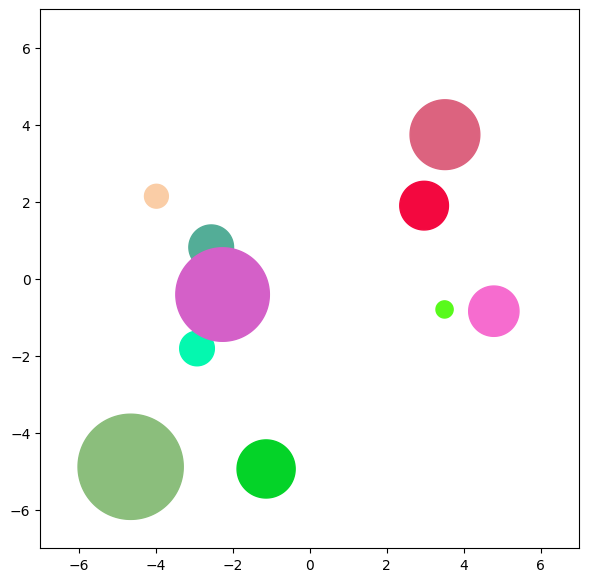

In [8]:
fig, ax = plt.subplots(figsize=(7, 7))

for i in range(10):
    x0 = np.random.uniform(-5, 5)
    y0 = np.random.uniform(-5, 5)
    R = np.random.uniform(0.2, 1.5)
    color = np.random.rand(3)

    draw_circle(x0, y0, R, color)

ax.set_xlim(-7, 7)
ax.set_ylim(-7, 7)
ax.set_aspect("equal")

plt.show()

## Q4: Climate

Download the data file of global surface air temperature averages from here:
https://raw.githubusercontent.com/sbu-python-summer/python-tutorial/master/day-4/nasa-giss.txt
This data comes from: https://data.giss.nasa.gov/gistemp/graphs/

(Don't ask, of course you can download data straight from python! Packages `requests` and `urllib` can both do the job)

There are 3 columns here: the year, the temperature change, and a smoothed representation of the temperature change.  

  * Read in this data using `np.loadtxt()`.  
  * Plot as a line the smoothed representation of the temperature changes.  
  * Plot as points the temperature change (no smoothing).  Color the points blue if they are < 0 and color them red if they are >= 0
  
You might find the numpy `where()` function useful.

In [9]:
url = "https://raw.githubusercontent.com/sbu-python-summer/python-tutorial/master/day-4/nasa-giss.txt"

response = requests.get(url)
response.raise_for_status()

with open("nasa-giss.txt", "wb") as f:
    f.write(response.content)

In [10]:
data = np.loadtxt("nasa-giss.txt")

In [11]:
year = data[:, 0]
temperature = data[:, 1]
smoothed = data[:, 2]

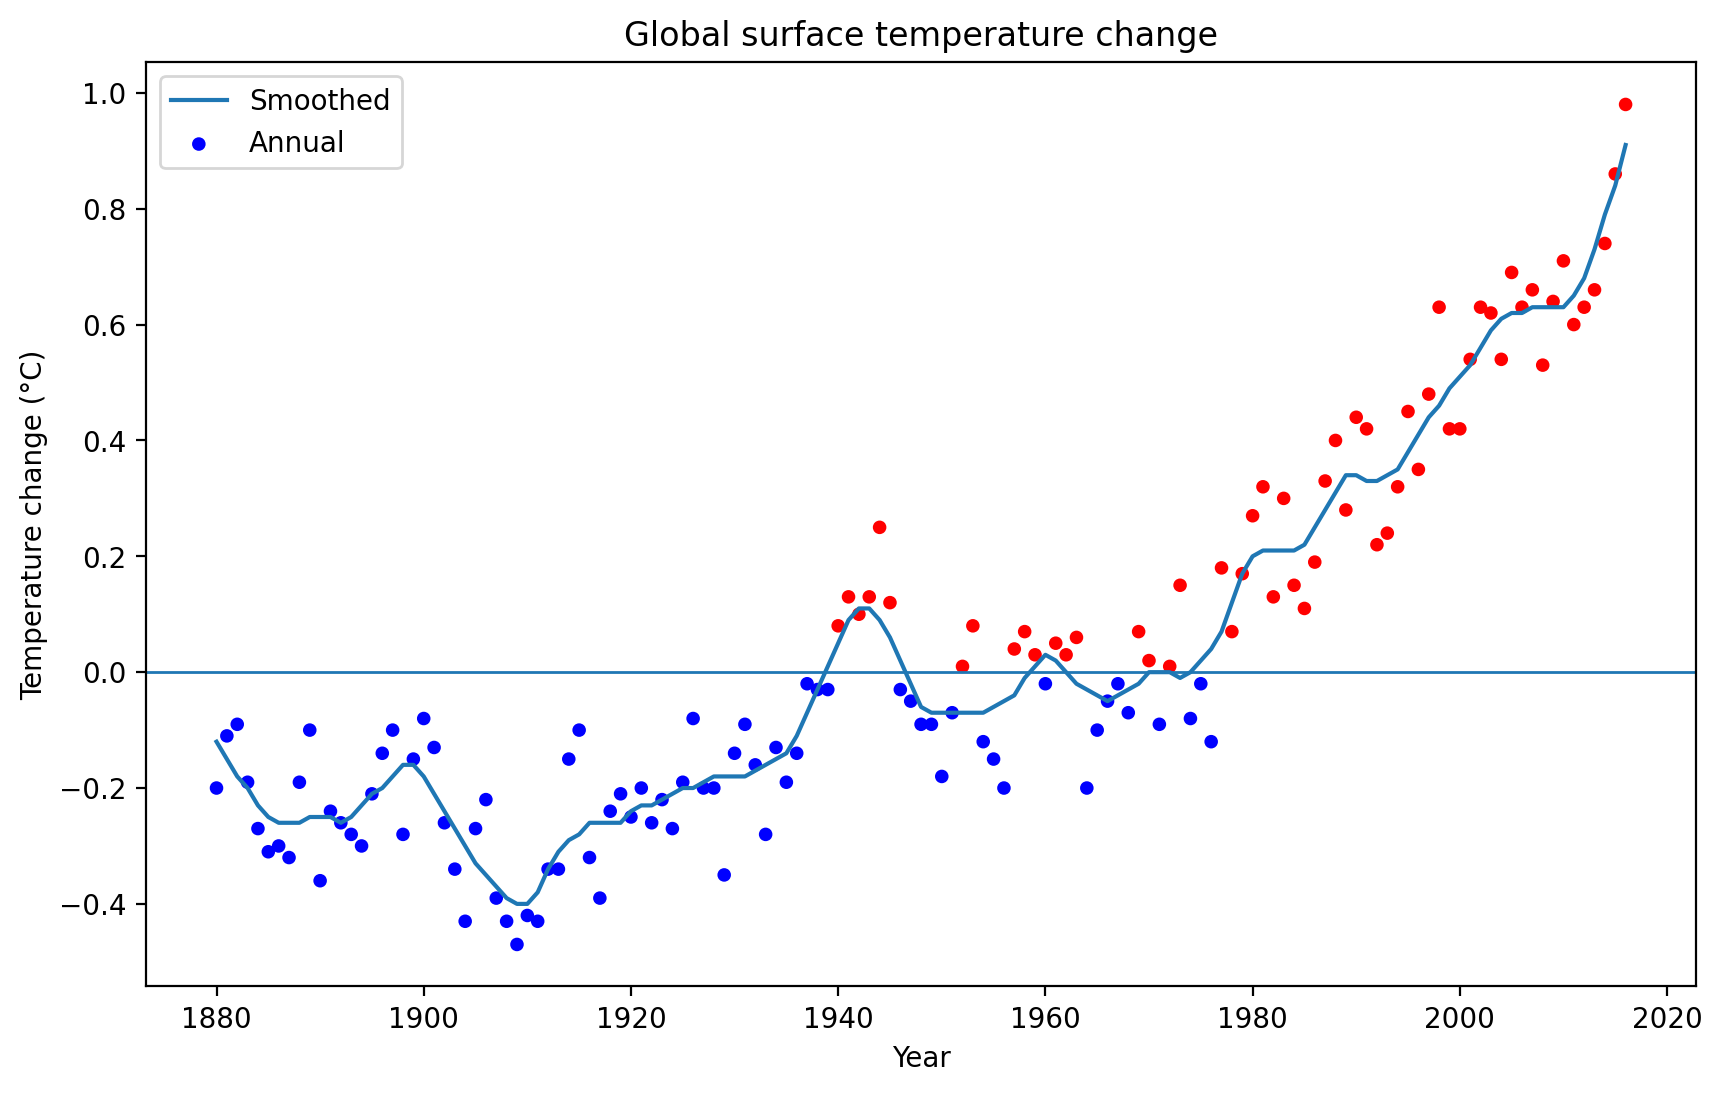

In [18]:
fig, ax = plt.subplots(figsize=(10, 6), dpi = 200)

ax.plot(year, smoothed, label="Smoothed")

colors = np.where(temperature < 0, "blue", "red")
ax.scatter(year, temperature, c=colors, s=15, label="Annual")

ax.axhline(0, linewidth=1)
ax.set_xlabel("Year")
ax.set_ylabel("Temperature change (°C)")
ax.set_title("Global surface temperature change")
ax.legend()

plt.show()

## Q5: Subplots

matplotlib has a number of ways to create multiple axes in a figure -- look at `plt.subplots()` (http://matplotlib.org/api/pyplot_api.html#matplotlib.pyplot.subplot)

Create an `x` array using NumPy with a number of points, spanning from $[0, 2\pi]$.  

Create 3 axes vertically, and do the following:

* Define a new numpy array `f` initialized to a function of your choice.
* Plot f in the top axes
* Compute a numerical derivative of `f`,
   $$ f' = \frac{f_{i+1} - f_i}{\Delta x}$$
  and plot this in the middle axes
* Do this again, this time on $f'$ to compute the second derivative and plot that in the bottom axes


In [13]:
x = np.linspace(0, 2*np.pi, 200)

In [14]:
f = np.sin(x)

In [15]:
dx = x[1] - x[0]

In [16]:
# First numerical derivative
f_prime = (f[1:] - f[:-1]) / dx
x_prime = x[:-1]

# Second numerical derivative
f_second = (f_prime[1:] - f_prime[:-1]) / dx
x_second = x_prime[:-1]

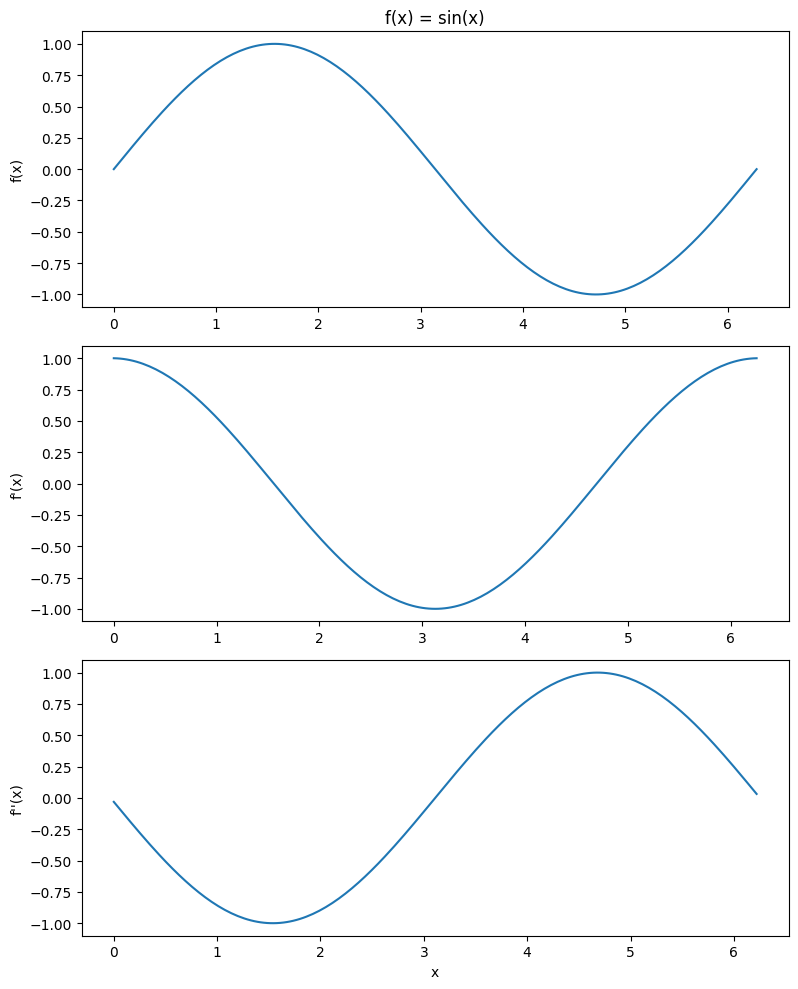

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(8, 10))

axes[0].plot(x, f)
axes[0].set_ylabel("f(x)")
axes[0].set_title("f(x) = sin(x)")

axes[1].plot(x_prime, f_prime)
axes[1].set_ylabel("f'(x)")

axes[2].plot(x_second, f_second)
axes[2].set_ylabel("f''(x)")
axes[2].set_xlabel("x")

plt.tight_layout()
plt.show()